<a href="https://colab.research.google.com/github/guyen5/Capstone/blob/main/notebooks/4%20Replication%20Run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4: Replication Run

This notebook replicates the two baselines of Wang and Hasuike (2026) on the project's data. **Plain PTO** forecasts each ETF's return with a ridge regression and passes the forecasts to the Markowitz optimizer. **Classic Markowitz** passes historical average returns to the same optimizer. Both run for every risk aversion λ in the paper's grid, on both universes, over the 81 test months, and the results are set against the paper's Table 3.

The run tests H1: plain PTO trades far more than classic Markowitz, and raising λ does not fix it. Every setting follows the Replication Spec, and the four pass criteria in the spec are checked in section 8. They were fixed before this run.

**Work packages:** WBS 3.4 (Replication run) and 3.45 (Ridge penalty diagnostic)

**Inputs:** Daily Features, Daily Training Windows and Covariances from Notebook 3, Monthly Data from Notebook 2, Daily Prices from Notebook 1

**Outputs** (Google Drive, `Capstone/data`):

| File | Folder | Contents |
|---|---|---|
| PTO Forecasts.parquet | processed | Each ETF's forecast return at each decision date, with the chosen ridge penalty |
| Replication Months.parquet | processed | Monthly gross and net return, fee and turnover of plain PTO and classic Markowitz, every λ and universe |
| Replication Results.csv | reports | Return, volatility, Sharpe ratio, drawdown and turnover of each run, next to the paper's values |
| Ridge Penalty Diagnostic.csv | reports | Plain PTO turnover, Sharpe ratio and forecast quality for each fixed ridge penalty |
| Replication Checks.csv | reports | Results of all checks, including the four pass criteria |

## 1. Setup

Connects Google Drive, where all data files are stored, and loads the project code from the GitHub repository. Run this cell first in every new Colab session.

**GitHub token (only if the repository is private).** The repository is public, so no token is needed. If it is ever made private, create a read-only fine-grained token on GitHub for the Capstone repository and add it in Colab's Secrets panel (key icon) as `GITHUB_TOKEN`, with notebook access turned on.

In [1]:
# Connect Google Drive. All data files are read from and saved to
# MyDrive/Capstone/data.
from google.colab import drive, userdata
drive.mount("/content/drive")

import os
import shutil
import subprocess
import sys

REPO = "guyen5/Capstone"
REPO_DIR = "/content/Capstone"

# The repository is public, so no login is needed. A GitHub token stored as
# the Colab secret GITHUB_TOKEN is used only if one exists, in case the
# repository is ever made private.
try:
    token = userdata.get("GITHUB_TOKEN")
except Exception:
    token = None
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

# Download a fresh copy of the code on every run, so the notebook always
# uses the latest version on GitHub. Stop if the download fails rather than
# run on an old copy.
shutil.rmtree(REPO_DIR + "_new", ignore_errors=True)
result = subprocess.run(["git", "clone", "--quiet", url, REPO_DIR + "_new"],
                        capture_output=True, text=True)
if result.returncode != 0:
    raise RuntimeError("Could not download the code from GitHub. Check that the repository "
                       "guyen5/Capstone is public, or add a GitHub token as the Colab secret GITHUB_TOKEN.")
shutil.rmtree(REPO_DIR, ignore_errors=True)
os.rename(REPO_DIR + "_new", REPO_DIR)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Install the pinned library versions listed in requirements.txt.
%pip install --quiet -r {REPO_DIR}/requirements.txt

# Make the project modules importable with "from src import ...".
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: 85b4873, Use a GitHub token to download the private repository in Colab (2026-10-26 01:19)



In [2]:
import importlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, cleaning, windows, covariance, variables, optimizer, backtest, forecast

# Reload the modules so code changes pulled from GitHub take effect
# without restarting the Colab runtime.
for module in (config, cleaning, windows, covariance, variables, optimizer, backtest, forecast):
    importlib.reload(module)

DIRS = config.data_dirs()
pd.set_option("display.width", 160)
checks = []

## 2. Load the inputs

The daily table and its training windows drive the forecasts; the holding-month returns, covariances and 126-day historical means drive the backtest. Only the paper's 9+3 window is used here.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}

assert (pd.DatetimeIndex(calendar["decision_date"]) == returns["ETF_A"].index).all()
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")
print(f"Classic Markowitz averages the last {config.MU_DAYS} trading days")

81 decision dates, 2020-01 to 2026-09
Classic Markowitz averages the last 126 trading days


## 3. Forecasts

At each decision date a ridge regression is fitted on the daily rows of the 9+3 window and predicts each ETF's return over the coming month. As set out in the Replication Spec:

- **Inputs:** the seven features, standardized on the rows being fitted, plus a 0/1 column for each ticker. One model is shared by all ETFs in a universe.
- **Target:** the 21-day forward return.
- **Penalty:** one of 15 values from 0.1 to 10⁶, chosen by squared error on the 3-month validation slice. While tuning, only rows whose targets are known before validation starts are fitted. The chosen model is then refit on the whole 12 months and predicts at the decision date.

A large penalty pulls every forecast toward the same value, the average return of the window. A small one lets the features and tickers separate the ETFs.

In [4]:
fc = pd.concat([forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u)) for u in universes],
               ignore_index=True)
per_month = fc.drop_duplicates(["universe", "date"])
print(f"{len(fc):,} forecasts, {per_month['fit_rows'].median():.0f} fit rows and "
      f"{per_month['validation_rows'].median():.0f} validation rows in a typical month")
print()
print("Chosen ridge penalty (share of months)")
print(per_month.groupby("universe")["alpha"].value_counts(normalize=True).unstack(0).fillna(0).round(2).to_string())

1,458 forecasts, 1504 fit rows and 560 validation rows in a typical month

Chosen ridge penalty (share of months)
universe   ETF_A  ETF_B
alpha                  
0.1         0.11   0.04
10.0        0.00   0.02
31.6        0.02   0.00
100.0       0.02   0.09
316.0       0.05   0.02
1000.0      0.09   0.10
3160.0      0.15   0.16
10000.0     0.06   0.05
31600.0     0.02   0.02
100000.0    0.02   0.05
316000.0    0.00   0.01
1000000.0   0.44   0.43


## 4. Checks on the forecasts

Confirms that every month has a forecast for every ETF, that no training target is later than its decision date, and that three random months refit with scikit-learn's `Ridge` give the same forecasts.

In [5]:
for u in universes:
    report = forecast.check_forecasts(fc, daily_table, calendar, u, backtest.tickers_of(u))
    print(u)
    print(report.to_string(index=False))
    print()
    checks.append(report.assign(table=f"PTO Forecasts {u}"))
fc_columns = variables.check_table(fc, "PTO Forecasts")
checks.append(fc_columns.assign(table="PTO Forecasts"))
print("Column checks:", fc_columns["status"].value_counts().to_dict())
if (pd.concat(checks)["status"] == "FAIL").any():
    raise RuntimeError("A forecast check failed.")

ETF_A
               check status                                                               detail
            complete   PASS                              81 months x 8 ETFs, no missing forecast
       no look-ahead   PASS                  every training target is known on its decision date
matches scikit-learn   PASS 3 random months refit with sklearn Ridge, largest difference 6.8e-17

ETF_B
               check status                                                               detail
            complete   PASS                             81 months x 10 ETFs, no missing forecast
       no look-ahead   PASS                  every training target is known on its decision date
matches scikit-learn   PASS 3 random months refit with sklearn Ridge, largest difference 5.9e-17

Column checks: {'PASS': 10}


## 5. How good are the forecasts

| Measure | Meaning |
|---|---|
| Out-of-sample R² | 1 minus squared forecast error relative to a forecast of zero. Monthly returns are mostly noise, so values near 0 are normal and negative values are common |
| Mean IC | Average monthly rank correlation between forecasts and realized returns across ETFs. 0 means no ranking skill |
| IC t-statistic | Mean IC divided by its standard error over the 81 months |
| Top pick beats average | Share of months in which the ETF with the highest forecast beat the universe average; 0.5 is chance |
| Spread ratio | Cross-sectional spread of forecasts divided by that of realized returns. Well below 1 means the forecasts are cautious |

The chart compares the average forecast across ETFs with the average realized return each month, the same view as the paper's Figure 1. The paper's PTO line stays close to zero, unlike its SPO line.

          oos_r2  mean_ic  ic_t_stat  top_pick_beats_average  spread_ratio
universe                                                                  
ETF_A     -0.040    0.039       0.74                   0.519         0.155
ETF_B     -0.044   -0.051      -1.03                   0.407         0.151


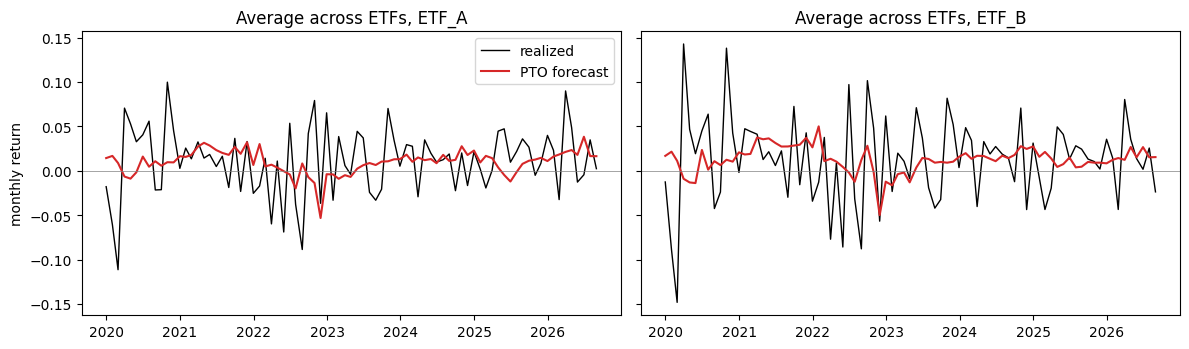

In [6]:
quality = forecast.forecast_quality(fc, panel)
print(quality.round(3).to_string())

realized = panel[["date", "universe", "ticker", "next_return"]]
m = fc.merge(realized, on=["date", "universe", "ticker"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, u in zip(axes, universes):
    g = m[m["universe"] == u].groupby("date")[["forecast", "next_return"]].mean()
    ax.plot(g.index, g["next_return"], color="black", lw=1, label="realized")
    ax.plot(g.index, g["forecast"], color="tab:red", lw=1.5, label="PTO forecast")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"Average across ETFs, {u}")
axes[0].set_ylabel("monthly return")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. The replication run

Both strategies use the same optimizer, the paper's sample covariance, κ = 0.005, a start from equal weights and the 0.5% fee. They differ only in the expected returns: the ridge forecasts for plain PTO, the 126-day historical means for classic Markowitz. Every month of every run is recomputed independently.

In [7]:
mu_pto = {u: fc[fc["universe"] == u].pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)]
          for u in universes}
runs, weights_by_run = [], {}
for u in universes:
    for name, mu in (("Plain PTO", mu_pto[u]), ("Classic Markowitz", hist_mu[u])):
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu, cov_sample[u], lam), returns[u])
            report = backtest.check_accounting(mo, w, returns[u])
            checks.append(report.assign(table=f"Backtest {u} {name} {lam}"))
            runs.append(mo.assign(strategy=name, universe=u, lam=lam))
            weights_by_run[(name, u, lam)] = w

rep_months = pd.concat(runs, ignore_index=True)[
    ["strategy", "universe", "lam", "date", "month", "gross", "fee", "net", "turnover", "held", "effective_n"]]
acc = pd.concat([c for c in checks if c["table"].iloc[0].startswith("Backtest")])
print(f"{rep_months.groupby(['strategy', 'universe', 'lam']).ngroups} runs; "
      f"accounting checks: {len(acc)} run, {(acc['status'] == 'FAIL').sum()} failed")
rm_columns = variables.check_table(rep_months, "Replication Months")
checks.append(rm_columns.assign(table="Replication Months"))
print("Column checks:", rm_columns["status"].value_counts().to_dict())
if (acc["status"] == "FAIL").any() or (rm_columns["status"] == "FAIL").any():
    raise RuntimeError("A backtest check failed.")

20 runs; accounting checks: 100 run, 0 failed
Column checks: {'PASS': 12}


## 7. Results next to Table 3

The first table covers the first 70 test months, the window the paper's turnover figures point to (Replication Spec). The full 81 months are saved alongside.

First 70 months
                                 turnover  paper_turnover  ann_vol  paper_ann_vol  sharpe  paper_sharpe  max_drawdown  paper_max_drawdown  effective_n
strategy          universe lam                                                                                                                        
Classic Markowitz ETF_A    0.1      0.170           0.194    0.196          0.248   0.717         0.654        -0.198              -0.312        1.004
                           1.0      0.180           0.248    0.178          0.236   0.780         0.440        -0.170              -0.312        1.324
                           10.0     0.127           0.142    0.097          0.108   0.519         0.285        -0.144              -0.213        2.136
                           20.0     0.081           0.091    0.072          0.078   0.392         0.248        -0.125              -0.170        2.019
                           50.0     0.046           0.045    0.061          0.

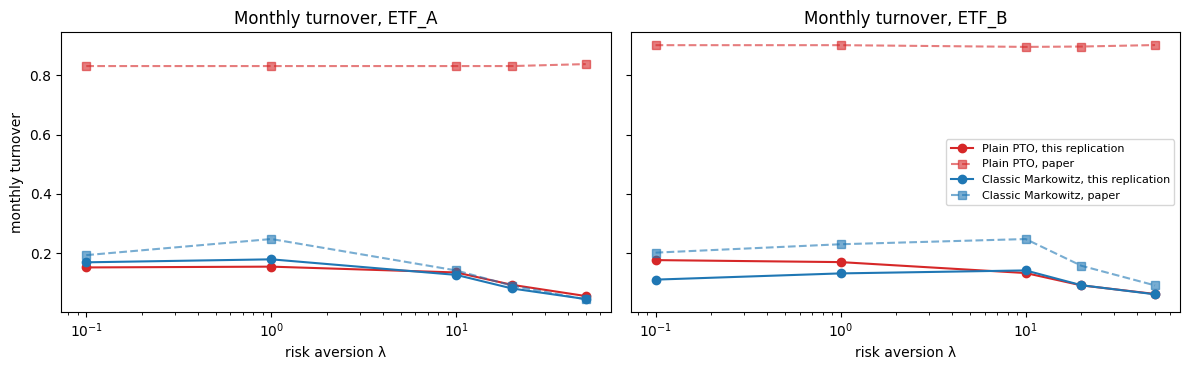

In [8]:
def summarize(rows):
    return pd.DataFrame([backtest.metrics(g).rename((s, u, l))
                         for (s, u, l), g in rows.groupby(["strategy", "universe", "lam"])])

full = summarize(rep_months)
first70 = summarize(rep_months[rep_months["month"] <= config.PAPER_LAST_MONTH])
metric_names = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover"]
paper = pd.concat([backtest.paper_rows("PTO").assign(strategy="Plain PTO"),
                   backtest.paper_rows("MVO").assign(strategy="Classic Markowitz")]
                  ).set_index(["strategy", "universe", "lam"])

def side_by_side(table):
    out = table[metric_names + ["effective_n"]].copy()
    out.index.names = ["strategy", "universe", "lam"]
    return out.join(paper.add_prefix("paper_"))

comparison70 = side_by_side(first70)
cols = ["turnover", "paper_turnover", "ann_vol", "paper_ann_vol", "sharpe", "paper_sharpe",
        "max_drawdown", "paper_max_drawdown", "effective_n"]
print("First 70 months")
print(comparison70[cols].round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, u in zip(axes, universes):
    for name, color in (("Plain PTO", "tab:red"), ("Classic Markowitz", "tab:blue")):
        s = comparison70.loc[(name, u)]
        ax.plot(s.index, s["turnover"], "o-", color=color, label=f"{name}, this replication")
        ax.plot(s.index, s["paper_turnover"], "s--", color=color, alpha=0.6, label=f"{name}, paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"Monthly turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Pass criteria

The four criteria from the Replication Spec, on ETF_A over the first 70 months:

1. Plain PTO turnover is at least 0.6 at every λ, and changes by less than 0.1 between λ = 0.1 and λ = 50.
2. Plain PTO turnover is at least three times classic Markowitz turnover at every λ from 10 up.
3. Classic Markowitz volatility falls at each step of the λ grid, and its turnover is below 0.3 at every λ.
4. Classic Markowitz volatility at λ = 10, 20 and 50 is within 30% of the paper's value.

Criteria 1 and 2 are H1. Criteria 3 and 4 confirm the optimizer and covariance are on the paper's scale. A failed criterion is reported as it stands; settings are not changed to make it pass.

In [9]:
pto = comparison70.loc[("Plain PTO", "ETF_A")].sort_index()
mvo = comparison70.loc[("Classic Markowitz", "ETF_A")].sort_index()
hi = [l for l in config.LAMBDA_GRID if l >= 10]
ratio = (pto.loc[hi, "turnover"] / mvo.loc[hi, "turnover"])
vol_gap = (mvo.loc[hi, "ann_vol"] / mvo.loc[hi, "paper_ann_vol"] - 1).abs()
change = abs(pto.loc[50.0, "turnover"] - pto.loc[0.1, "turnover"])
criteria = pd.DataFrame([
    {"check": "1. PTO trades heavily at every λ",
     "status": "PASS" if (pto["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
     "detail": f"turnover {pto['turnover'].min():.3f} to {pto['turnover'].max():.3f}; "
               f"change from λ = 0.1 to 50: {change:.3f}"},
    {"check": "2. PTO trades 3x Markowitz at λ ≥ 10",
     "status": "PASS" if (ratio >= 3).all() else "FAIL",
     "detail": "ratios " + ", ".join(f"{r:.1f}" for r in ratio)},
    {"check": "3. Markowitz volatility falls, turnover < 0.3",
     "status": "PASS" if (mvo["ann_vol"].diff().dropna() < 0).all() and (mvo["turnover"] < 0.3).all() else "FAIL",
     "detail": "volatility " + ", ".join(f"{v:.3f}" for v in mvo["ann_vol"])
               + f"; turnover up to {mvo['turnover'].max():.3f}"},
    {"check": "4. Markowitz volatility within 30% of paper",
     "status": "PASS" if (vol_gap <= 0.3).all() else "FAIL",
     "detail": "gaps " + ", ".join(f"{g:.0%}" for g in vol_gap) + " at λ = 10, 20, 50"},
])
print(criteria.to_string(index=False))
checks.append(criteria.assign(table="Pass criteria"))

                                        check status                                                             detail
             1. PTO trades heavily at every λ   FAIL          turnover 0.056 to 0.155; change from λ = 0.1 to 50: 0.096
         2. PTO trades 3x Markowitz at λ ≥ 10   FAIL                                               ratios 1.1, 1.2, 1.2
3. Markowitz volatility falls, turnover < 0.3   PASS volatility 0.196, 0.178, 0.097, 0.072, 0.061; turnover up to 0.180
  4. Markowitz volatility within 30% of paper   PASS                                 gaps 10%, 8%, 7% at λ = 10, 20, 50


## 9. What the PTO portfolio holds

The weights of plain PTO and classic Markowitz on ETF_A at λ = 20, month by month. A portfolio that jumps from one block of colour to another is switching most of its money between ETFs. The table gives the share of months in which one ETF holds more than 90% of the portfolio.

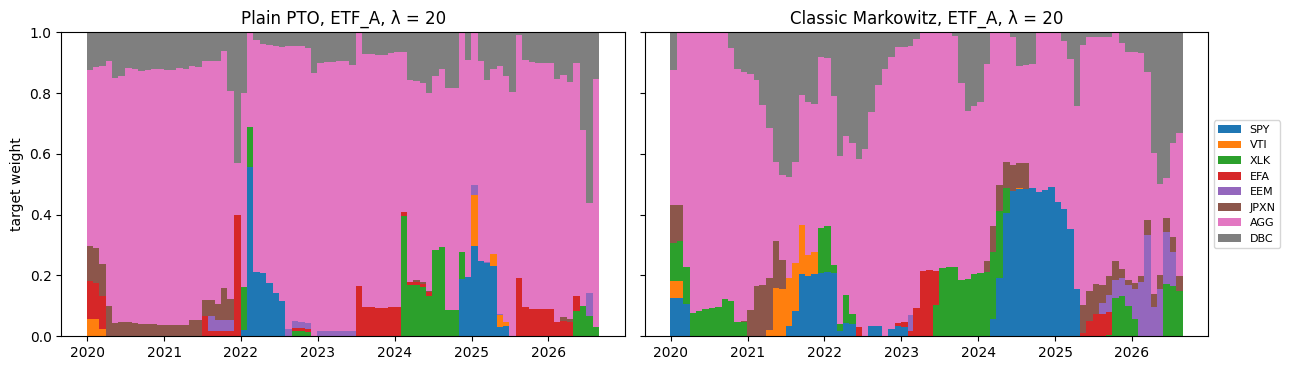

lam                         0.1   1.0   10.0  20.0  50.0
strategy          universe                              
Classic Markowitz ETF_A     0.99  0.61  0.00  0.10  0.17
                  ETF_B     0.83  0.60  0.00  0.00  0.00
Plain PTO         ETF_A     0.73  0.47  0.06  0.06  0.04
                  ETF_B     0.66  0.29  0.13  0.00  0.00


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
colors = plt.cm.tab10(np.arange(len(config.ETF_A)))
for ax, name in zip(axes, ("Plain PTO", "Classic Markowitz")):
    w = weights_by_run[(name, "ETF_A", 20.0)].pivot(index="date", columns="ticker", values="target")[config.ETF_A]
    ax.stackplot(w.index, w.T.to_numpy(), labels=config.ETF_A, colors=colors, step="post")
    ax.set_title(f"{name}, ETF_A, λ = 20")
    ax.set_ylim(0, 1)
axes[0].set_ylabel("target weight")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
plt.tight_layout()
plt.show()

single = []
for (name, u, lam), w in weights_by_run.items():
    top = w.groupby("date")["target"].max()
    top = top[top.index <= pd.Timestamp(config.PAPER_LAST_MONTH) - pd.offsets.MonthEnd(1)]
    single.append({"strategy": name, "universe": u, "lam": lam, "one ETF above 90%": (top > 0.9).mean()})
print(pd.DataFrame(single).pivot_table(index=["strategy", "universe"], columns="lam",
                                       values="one ETF above 90%").round(2).to_string())

## 11. Ridge penalty diagnostic (WBS 3.45)

Criteria 1 and 2 fail: plain PTO trades only 0.06 to 0.16 a month on ETF_A, against 0.83 in the paper. The forecasts are the likely cause. Validation chose the largest ridge penalty in about 44% of months, which pulls every ETF's forecast toward the same value, and the forecasts' spread across ETFs is only 15% of that of realized returns. Differences that small rarely beat the trading penalty, so the portfolio stays put. The paper describes its PTO model only as a linear predictor trained on squared error, which suggests little or no shrinkage.

This section traces that cause. Plain PTO is rerun with the ridge penalty fixed at 0.1, 10, 10³, 10⁴, 10⁵ and 10⁶ instead of chosen on validation. Everything else is unchanged.

A second possible cause is shown alongside. The 9+3 window holds about 1,500 overlapping daily rows, so even an unpenalized fit averages over many similar rows and moves slowly from month to month. If the paper fitted one row per ETF and month (72 rows on ETF_A), its forecasts would be far noisier. The column "0.1, month-end rows" refits the least-penalized model on month-end rows only. It is reported for the trace and is not part of the rule below.

**Rule, fixed before the results are seen.** If the least-penalized model (0.1, close to ordinary least squares) passes criteria 1 and 2 on ETF_A over the first 70 months, it becomes plain PTO for the rest of the project, as the closest match to the paper's linear predictor. The validation-tuned version is then kept as a comparison strategy: it is itself a form of uniform shrinkage, which H3 compares against. If the least-penalized model also fails, the replication is reported as not reproducing the paper's PTO turnover, and the cause is investigated further before any extension is built.

In [11]:
diag_rows, quality_rows = [], []
mvo70 = comparison70.loc["Classic Markowitz"]
variants = [(a, False) for a in config.PTO_ALPHA_GRID] + [(config.PTO_ALPHA_GRID[0], True)]
for alpha, monthly in variants:
    label = f"{alpha:g}, month-end rows" if monthly else alpha
    fa = pd.concat([forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u), alphas=[alpha],
                                             month_end_only=monthly)
                    for u in universes], ignore_index=True)
    q = forecast.forecast_quality(fa, panel)
    for u in universes:
        quality_rows.append({"alpha": label, "universe": u, **q.loc[u].to_dict()})
        mu_a = fa[fa["universe"] == u].pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)]
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu_a, cov_sample[u], lam), returns[u])
            s = backtest.metrics(mo[mo["month"] <= config.PAPER_LAST_MONTH])
            diag_rows.append({"alpha": label, "universe": u, "lam": lam,
                              **s[["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover", "effective_n"]].to_dict(),
                              "markowitz_turnover": mvo70.loc[(u, lam), "turnover"],
                              "paper_turnover": paper.loc[("Plain PTO", u, lam), "turnover"],
                              "paper_sharpe": paper.loc[("Plain PTO", u, lam), "sharpe"]})

pen = pd.DataFrame(diag_rows)
pen_quality = pd.DataFrame(quality_rows)
tuned = comparison70.loc["Plain PTO"].reset_index()
view = pen.pivot_table(index=["universe", "lam"], columns="alpha", values="turnover", sort=False)
view["tuned"] = tuned.set_index(["universe", "lam"])["turnover"]
view["paper"] = pen.drop_duplicates(["universe", "lam"]).set_index(["universe", "lam"])["paper_turnover"]
print("Plain PTO monthly turnover by ridge penalty, first 70 months")
print(view.round(3).to_string())
print()
print("Forecast quality by ridge penalty")
print(pen_quality.pivot_table(index="alpha", columns="universe", sort=False,
                              values=["spread_ratio", "mean_ic", "oos_r2"]).round(3).to_string())

Plain PTO monthly turnover by ridge penalty, first 70 months
alpha            0.1   10.0  1000.0  10000.0  100000.0  1000000.0  0.1, month-end rows  tuned  paper
universe lam                                                                                        
ETF_A    0.1   0.341  0.342   0.260    0.041     0.000      0.000                0.425  0.152  0.831
         1.0   0.348  0.342   0.260    0.041     0.004      0.004                0.426  0.155  0.831
         10.0  0.282  0.276   0.130    0.018     0.011      0.011                0.413  0.135  0.831
         20.0  0.198  0.192   0.081    0.017     0.013      0.013                0.321  0.094  0.831
         50.0  0.103  0.101   0.045    0.019     0.018      0.018                0.179  0.056  0.838
ETF_B    0.1   0.399  0.384   0.330    0.084     0.000      0.000                0.635  0.177  0.901
         1.0   0.415  0.407   0.342    0.082     0.001      0.001                0.619  0.170  0.901
         10.0  0.313  0.303   

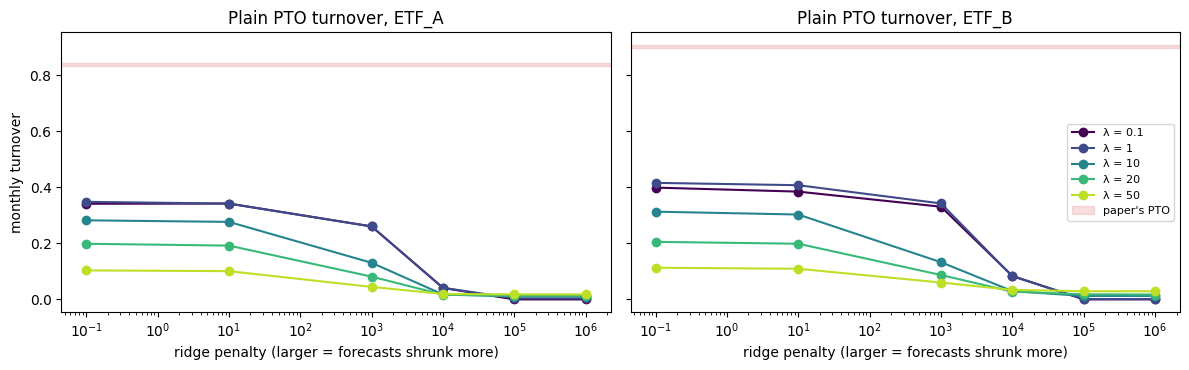

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(config.LAMBDA_GRID)))
for ax, u in zip(axes, universes):
    fixed = pen[pen["alpha"].map(lambda a: not isinstance(a, str))]
    for lam, c in zip(config.LAMBDA_GRID, colors):
        s = fixed[(fixed["universe"] == u) & (fixed["lam"] == lam)]
        ax.plot(s["alpha"], s["turnover"], "o-", color=c, label=f"λ = {lam:g}")
    ax.axhspan(pen.loc[pen["universe"] == u, "paper_turnover"].min(),
               pen.loc[pen["universe"] == u, "paper_turnover"].max() + 0.005,
               color="tab:red", alpha=0.15, label="paper's PTO")
    ax.set_xscale("log")
    ax.set_xlabel("ridge penalty (larger = forecasts shrunk more)")
    ax.set_title(f"Plain PTO turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
rows = []
hi = [l for l in config.LAMBDA_GRID if l >= 10]
for alpha in [v[0] if not v[1] else f"{v[0]:g}, month-end rows" for v in variants]:
    a = pen[(pen["universe"] == "ETF_A") & (pen["alpha"] == alpha)].set_index("lam").sort_index()
    change = abs(a.loc[50.0, "turnover"] - a.loc[0.1, "turnover"])
    c1 = bool((a["turnover"] >= 0.6).all() and change < 0.1)
    c2 = bool((a.loc[hi, "turnover"] / a.loc[hi, "markowitz_turnover"] >= 3).all())
    rows.append({"alpha": alpha, "turnover range": f"{a['turnover'].min():.2f} to {a['turnover'].max():.2f}",
                 "change λ 0.1 to 50": round(change, 3),
                 "ratio to Markowitz at λ ≥ 10": ", ".join(f"{r:.1f}" for r in a.loc[hi, "turnover"] / a.loc[hi, "markowitz_turnover"]),
                 "criterion 1": "PASS" if c1 else "FAIL", "criterion 2": "PASS" if c2 else "FAIL",
                 "mean Sharpe": round(a["sharpe"].mean(), 3)})
penalty_criteria = pd.DataFrame(rows).astype({"alpha": str})
print("Criteria 1 and 2 on ETF_A, first 70 months, for each fixed penalty")
print(penalty_criteria.to_string(index=False))
least = penalty_criteria.iloc[0]
print()
if least["criterion 1"] == "PASS" and least["criterion 2"] == "PASS":
    print(f"Rule: the least-penalized model (alpha = {config.PTO_ALPHA_GRID[0]}) passes criteria 1 and 2. "
          "It becomes plain PTO; the validation-tuned version is kept as a comparison.")
else:
    print(f"Rule: the least-penalized model (alpha = {config.PTO_ALPHA_GRID[0]}) does not pass both criteria. "
          "The replication does not reproduce the paper's PTO turnover; the cause needs further work.")
checks.append(penalty_criteria.assign(table="Ridge penalty diagnostic", check="alpha " + penalty_criteria["alpha"].astype(str),
                                      status=np.where((penalty_criteria["criterion 1"] == "PASS") & (penalty_criteria["criterion 2"] == "PASS"), "PASS", "FAIL"),
                                      detail=penalty_criteria["turnover range"])[["check", "status", "detail", "table"]])

Criteria 1 and 2 on ETF_A, first 70 months, for each fixed penalty
              alpha turnover range  change λ 0.1 to 50 ratio to Markowitz at λ ≥ 10 criterion 1 criterion 2  mean Sharpe
                0.1   0.10 to 0.35               0.238                2.2, 2.4, 2.3        FAIL        FAIL        0.215
               10.0   0.10 to 0.34               0.241                2.2, 2.4, 2.2        FAIL        FAIL        0.196
             1000.0   0.04 to 0.26               0.216                1.0, 1.0, 1.0        FAIL        FAIL        0.101
            10000.0   0.02 to 0.04               0.021                0.1, 0.2, 0.4        FAIL        FAIL        0.442
           100000.0   0.00 to 0.02               0.018                0.1, 0.2, 0.4        FAIL        FAIL        0.422
          1000000.0   0.00 to 0.02               0.018                0.1, 0.2, 0.4        FAIL        FAIL        0.427
0.1, month-end rows   0.18 to 0.43               0.246                3.3, 3.9, 3.9   

## 12. Save

Saves the forecasts, the monthly results, the summary next to the paper, the penalty diagnostic and every check.

In [14]:
fc.to_parquet(proc / config.FILES["forecasts"], index=False)
rep_months.to_parquet(proc / config.FILES["replication_months"], index=False)
results = pd.concat([side_by_side(full).assign(window="81 months"), comparison70.assign(window="70 months")])
results.reset_index().to_csv(DIRS["reports"] / config.FILES["replication_results"], index=False)
all_checks = pd.concat(checks, ignore_index=True)
all_checks.to_csv(DIRS["reports"] / config.FILES["replication_checks"], index=False)
pen.merge(pen_quality, on=["alpha", "universe"]).to_csv(DIRS["reports"] / config.FILES["penalty_diagnostic"], index=False)
print("Saved: PTO Forecasts, Replication Months, Replication Results, Replication Checks,\n"
      "       Ridge Penalty Diagnostic")

Saved: PTO Forecasts, Replication Months, Replication Results, Replication Checks,
       Ridge Penalty Diagnostic


## 13. Summary

Key figures for the process log. After the run, save the notebook (File > Save a copy in GitHub) so the outputs are kept.

In [15]:
passed = int((all_checks["status"] == "PASS").sum())
failed = int((all_checks["status"] == "FAIL").sum())
a = comparison70.xs("ETF_A", level="universe")
print(f"Forecasts:      {len(fc):,} ({len(calendar)} months, both universes)")
print(f"ETF_A, 70 months, plain PTO turnover:        {a.loc['Plain PTO', 'turnover'].min():.2f} to {a.loc['Plain PTO', 'turnover'].max():.2f} (paper 0.83 to 0.84)")
print(f"ETF_A, 70 months, classic Markowitz turnover: {a.loc['Classic Markowitz', 'turnover'].min():.2f} to {a.loc['Classic Markowitz', 'turnover'].max():.2f} (paper 0.05 to 0.25)")
print(f"Pass criteria:  {', '.join(criteria['status'])} (validation-tuned penalty)")
print(f"Least-penalized PTO (alpha = {config.PTO_ALPHA_GRID[0]}): criterion 1 {least['criterion 1']}, criterion 2 {least['criterion 2']}")
print(f"Checks:         {passed} passed, {failed} failed")

Forecasts:      1,458 (81 months, both universes)
ETF_A, 70 months, plain PTO turnover:        0.06 to 0.16 (paper 0.83 to 0.84)
ETF_A, 70 months, classic Markowitz turnover: 0.05 to 0.18 (paper 0.05 to 0.25)
Pass criteria:  FAIL, FAIL, PASS, PASS (validation-tuned penalty)
Least-penalized PTO (alpha = 0.1): criterion 1 FAIL, criterion 2 FAIL
Checks:         130 passed, 9 failed
